<!-- DRAFT: Graeme to edit -->
# Day 2 · 05b (full data) — Lab: teaching price response with synthetic discounts (15 min)

05's price response is learnt from the discounts the shop actually ran. Those are few, short
and bunched in the same series. Here we try a research idea from phase 7: **plant extra
one-week price cuts** in the oversampled training copies, each with a known lift, and see
whether the model learns from them. This is **experimental**: the research tried it but never
accepted it (`docs/gfm_learnings.md` §5, [100k set]).

| | |
|---|---|
| Starts from | the selected 05 model |
| Adds | two one-week cuts per oversampled copy, 10–30% deep, with a planted lift |
| Originals | untouched: only the copies get synthetic weeks |
| Measured | the sweep, the phase 7b probes and calendars, and an **echo check** |
| Decides | whether 06–10 use 05 or 05b, by a rule written before the results |

Goals

1. Build 05's training data with and without synthetic cuts, and see what was planted.
2. Choose between 05 and 05b by a rule on the validation window (3 seeds each).
3. Fit 05's model on the synthetic data (3 seeds) and score the test window once.
4. Check whether the model gives back the lift we planted.

**In the chain:** reads `05_selected`, `04_price`, `02_shortlist` and `00_baselines`, writes
`05b_synthetic`. Its `use` key tells `gd.selected_config()` whether 06–10 build on 05 or 05b.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import gd_helpers as gd
import gd_plots as gplt
import gd_price as gp

bc = gd.bc
gd.status()
gplt.use_style()

/home/gdavidson/code/time-series-forecasting-bootcamp/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LOAD (read saved results) | results: results/day2_full | accelerator: gpu


<!-- DRAFT: Graeme to edit -->
## Intuition: worked examples with the answer written in

![Ask the model 'what if?'](../slides/img/response_sketch.png)

A model learns price response from weeks where the price moved. If the shop rarely cuts prices
outside a few promotions, there is little to learn from. Synthetic cuts are worked examples in
a textbook. In a copy of a series we lower the price for one week and raise its sales by a lift
we choose. If the model learnt from them, a probe with the same cut should **echo** back
roughly that lift. The risk is that it learns our made-up rule rather than the shop's
customers, so we check accuracy on real test weeks too.

<!-- DRAFT: Graeme to edit -->
## 1. From 05's config to 05b's

05b is 05's config plus one key, `synthetic`. The cuts are planted with **one fixed random
seed** for all three training seeds. So the fits see the same data, and their spread is
training noise only, as in 05.

In [2]:
baselines_cfg = gd.load_config("00_baselines")
noise_floor = gd.load_config("02_shortlist")["noise_floor"]
price_cfg = gd.load_config("04_price")
cfg_a = gd.load_config("05_selected")
price_channel = price_cfg.get("price_channel", "price_index")
examples = baselines_cfg["examples"]
example_ids = gplt.example_ids(examples)

cfg_b = dict(cfg_a)
oversample_added = not cfg_a.get("oversample")
if oversample_added:      # synthetic cuts live in the copies, so they need oversampling
    cfg_b["oversample"] = price_cfg.get("oversample") or {
        "rule": "rolling", "cap": gp.COPY_CAP, "multiplier": gp.COPY_MULTIPLIER}
    print("05 has no oversampling: 05b adds 04's default, so it differs from 05 in two ways.")
cfg_b["synthetic"] = {"cuts_per_copy": 2}
synthetic_seed = bc.RANDOM_SEED

raw = gd.train_panel()
panel, train, test, data_a = gp.prepare(cfg_a, panel=raw)
_, _, _, data_b = gp.prepare(cfg_b, panel=raw, synthetic_seed=synthetic_seed)
info = gplt.series_table(panel)
report_ids = gp.report_ids(train)

params = cfg_a["params"]
max_steps = cfg_a["max_steps"]
if oversample_added:
    max_steps = gd.scaled_max_steps(data_b.fit_df["unique_id"].nunique(),
                                    batch_size=params.get("batch_size", 256))
print(f"{data_b.fit_df['unique_id'].nunique():,} training series incl. copies | "
      f"{max_steps:,} steps | {len(report_ids):,} report series | seeds {gd.SEEDS}")
pd.Series({"oversample": cfg_b["oversample"], "synthetic": cfg_b["synthetic"],
           "synthetic_seed": synthetic_seed, "price_channel": price_channel})

40,079 training series incl. copies | 11,718 steps | 680 report series | seeds [46335, 11207, 90218]


oversample        {'rule': 'rolling', 'cap': 15, 'multiplier': 5}
synthetic                                    {'cuts_per_copy': 2}
synthetic_seed                                              46335
price_channel                                         price_index
dtype: object

<!-- DRAFT: Graeme to edit -->
### What was planted

Each copy is its original series with a few weeks changed. Comparing them row by row finds
the planted weeks: lower price, higher units. The table counts them by depth, with the lift
we asked for and the lift that landed (units are whole numbers, so small sellers round).

The planted lifts imply an elasticity of roughly −3 to −5 (lift ÷ cut: +60% for a 20% cut is
−3). That is close to the ≈ −3.6 measured on this data (`docs/progress.md`), and far stronger
than the research's −0.4 to −0.7 [100k set]. This panel's price variation is mostly short
promo cuts with big short-term lifts.

In [3]:
def planted_weeks(fit_df: pd.DataFrame, y_shift: float) -> pd.DataFrame:
    """Weeks where a copy's price differs from its original series': depth and lift."""
    is_copy = fit_df["unique_id"].str.contains(gp.COPY_TAG, regex=False)
    copies = fit_df[is_copy].copy()
    copies["original"] = copies["unique_id"].str.split(gp.COPY_TAG).str[0]
    originals = fit_df[~is_copy].rename(columns={"unique_id": "original"})
    both = copies.merge(originals, on=["original", "ds"], suffixes=("_b", "_a"))
    both = both[~np.isclose(both["price_index_a"], both["price_index_b"])].copy()
    both["depth"] = (1 - both["price_index_b"] / both["price_index_a"]).round(2)
    units_a = both["y_a"] - y_shift
    both["lift"] = (both["y_b"] - y_shift) / units_a.where(units_a > 0) - 1
    return both[["unique_id", "ds", "depth", "lift"]]


planted = planted_weeks(data_b.fit_df, data_b.y_shift)
planted_table = planted.groupby("depth").agg(weeks=("lift", "size"),
                                             median_lift_landed=("lift", "median"))
planted_table["lift_asked"] = planted_table.index.map(gp.SYNTHETIC_LIFT)
print(f"{len(planted):,} planted weeks in {planted['unique_id'].nunique():,} copies")
planted_table.round(2)

44,666 planted weeks in 22,423 copies


,weeks,median_lift_landed,lift_asked
depth,,,
0.10,8966,0.35,0.35
0.15,8869,0.45,0.45
0.20,8986,0.60,0.60
0.25,8905,1.00,1.00
0.30,8940,1.50,1.50


<!-- DRAFT: Graeme to edit -->
## 2. The rule, written before the results

Notebooks 06–10 use 05b **only if all three hold**; otherwise they keep 05. Every check reads
the **validation window**: 05's config and 05b's are each fitted with 3 seeds on the weeks
before `VALID_START`, and probed on that window's report series (seed-mean responses).

1. 05b's median elasticity for a **one-week 20% cut** is **more negative** than 05's. The
   price falls in one week and every input built from price (`discount_depth`) is rebuilt to
   match, as in a real discount week (`gp.price_probes`, mode `pulse_all`).
2. its share of **right-signed cuts** under **random promotion calendars** is **higher**
   than 05's: three one-week cuts per series, 10–30% deep, in ordinary weeks, five draws
   (`gp.promo_calendars`).
3. its median validation RMSSE is no more than the 02 noise floor above 05's.

The first two ask for a stronger, more consistent price response, measured as the forecasts
would be used: a discount week with all its inputs. The third says it must not cost real
accuracy. The test window is scored once afterwards, as the reported outcome.

*An earlier version of this rule moved `price_index` alone, over all 14 weeks, so a cut came
with no discount depth. The probes in `gp` explain the difference; `median_e20` from the old
sweep is still reported alongside.*

<!-- DRAFT: Graeme to edit -->
## 3. Choosing on the validation window

Both configs are rebuilt with `cutoff=bc.VALID_START`, so the reference price, the copies and
the planted cuts all come from the weeks before it. Each is fitted with the same 3 seeds.

In [4]:
_, inner_train, valid, valid_a = gp.prepare(cfg_a, panel=raw, cutoff=bc.VALID_START)
valid_b = gp.prepare(cfg_b, panel=raw, synthetic_seed=synthetic_seed,
                     cutoff=bc.VALID_START)[3]
valid_report_ids = gp.report_ids(inner_train)
valid_calendars = gp.promo_calendars(valid_a.futr_df, valid_report_ids)
max_steps_a = cfg_a["max_steps"]
print(f"validation: {valid_b.fit_df['unique_id'].nunique():,} training series incl. copies | "
      f"{len(valid_report_ids):,} report series | {len(valid_calendars):,} calendar cuts")
print("price inputs rebuilt from price_index, largest gap from the data:",
      gp.rebuild_check(gd.only(valid_a.predict_df, valid_report_ids),
                       gd.only(valid_a.futr_df, valid_report_ids)))


def valid_extras(nf, data):
    """Sweep and phase 7b probes on the validation window, while the model is in memory."""
    return {"sweep": gp.price_sweep(nf, data, valid_report_ids, channel=price_channel),
            **gp.gfm_probes(nf, data, valid_report_ids, valid_calendars)}


def model_05_valid(seed):
    return gd.build_nbeatsx(params, valid_a, max_steps_a, seed, "GFM_selected")


def model_05b_valid(seed):
    return gd.build_nbeatsx(params, valid_b, max_steps, seed, "GFM_synthetic")


PROBE_RUNS = "_p7b"          # run-name suffix: fits cached with the phase 7b probes
with bc.Timer() as t:
    valid_runs = {"05": gd.fit_seeds(model_05_valid, valid_a, "05b_valid_05" + PROBE_RUNS,
                                     extras=valid_extras),
                  "05b": gd.fit_seeds(model_05b_valid, valid_b, "05b_valid_05b" + PROBE_RUNS,
                                      extras=valid_extras)}
if gd.TRAIN:
    print(f"validation fits: {t.seconds / 60:.1f} min")

validation: 38,251 training series incl. copies | 680 report series | 8,434 calendar cuts
price inputs rebuilt from price_index, largest gap from the data: 3.3306690738754696e-16


2026-11-25 14:52:43,316	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-11-25 14:52:43,481	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [5]:
def seed_mean(frames: list[pd.DataFrame], keys: list[str]) -> pd.DataFrame:
    """Average the numeric columns of per-seed frames that share ``keys``."""
    return pd.concat(frames).groupby(keys, as_index=False).mean(numeric_only=True)


def response_numbers(runs: list[dict]) -> dict:
    """The rule's response numbers for the seed-mean model of ``runs``."""
    probes = gp.probe_report(gp.seed_mean_q([r["probe7b"] for r in runs], gp.PROBE_KEYS))
    calendar = gp.probe_response(gp.seed_mean_q([r["calendar"] for r in runs], gp.CAL_KEYS))
    return {"cut20_elasticity": gp.headline(probes)["median_elasticity"],
            "cut20_lift": gp.headline(probes)["median_lift"],
            "calendar_right_sign": float(calendar["right_sign"].mean()),
            "median_e20": gp.elasticity_report(gp.arc_elasticity(gp.seed_mean_sweep(runs)))
            ["median_e20"]}


valid_numbers = {}
for name, runs in valid_runs.items():
    fcst = gd.seed_forecasts(runs)
    mean_col = [c for c in fcst.columns if c.endswith("_mean")][0]
    rmsse = gd.per_series(gd.score(fcst[["unique_id", "ds", mean_col]], valid, inner_train))
    valid_numbers[name] = {**response_numbers(runs),
                           "median_rmsse": float(rmsse[mean_col].median())}
valid_numbers = pd.DataFrame(valid_numbers).T

checks = {
    "stronger response (one-week 20% cut, more negative)":
        valid_numbers.loc["05b", "cut20_elasticity"] < valid_numbers.loc["05", "cut20_elasticity"],
    "more right-signed cuts (random calendars)":
        valid_numbers.loc["05b", "calendar_right_sign"]
        > valid_numbers.loc["05", "calendar_right_sign"],
    "accuracy within the noise floor":
        valid_numbers.loc["05b", "median_rmsse"] - valid_numbers.loc["05", "median_rmsse"]
        <= noise_floor,
}
use = "05b" if all(checks.values()) else "05"
print(f"later notebooks use: {use}")
valid_numbers.round(4)

later notebooks use: 05


,cut20_elasticity,cut20_lift,calendar_right_sign,median_e20,median_rmsse
05,-1.7697,0.4895,0.9942,-1.3693,0.5825
05b,-1.7697,0.4895,0.9959,-1.4122,0.5931


In [6]:
pd.Series(checks)

stronger response (one-week 20% cut, more negative)    False
more right-signed cuts (random calendars)               True
accuracy within the noise floor                        False
dtype: bool

<!-- DRAFT: Graeme to edit -->
### Reading the result

* The one-week 20% cut is a tie: both models give a median elasticity of ≈ −1.77 (a lift of
  ≈ +49%), equal to the third decimal. The planted cuts did not make the response stronger.
* Under the random calendars 05b gets slightly more cuts right-signed (≈ 99.6% against
  ≈ 99.4%), but both are close to every cut.
* 05b's validation RMSSE is ≈ 0.593 against 05's ≈ 0.583, a gap of about twice the noise
  floor (≈ 0.005). So 05b fails two of the three checks and later notebooks keep 05.

*Exact numbers vary with seed and hardware.*

<!-- DRAFT: Graeme to edit -->
## 4. Fit 05's model on the synthetic data, all training weeks (3 seeds)

The choice is made; these fits are the reported result. While each model is in memory, we
run the single-channel sweep and the phase 7b probes on the report series, and the price
scenarios on the example series. Only the first seed is saved, for later notebooks. The
random calendars are drawn once, so every model and seed meets the same promotions.

In [7]:
calendars = gp.promo_calendars(data_a.futr_df, report_ids)
print(f"test window: {len(calendars):,} calendar cuts over {gp.CAL_DRAWS} draws | price inputs "
      "rebuilt, largest gap from the data:",
      gp.rebuild_check(gd.only(data_a.predict_df, report_ids),
                       gd.only(data_a.futr_df, report_ids)))


def price_extras(nf, data):
    """Sweep, probes and example scenarios, computed while the model is in memory."""
    return {"sweep": gp.price_sweep(nf, data, report_ids, channel=price_channel),
            **gp.gfm_probes(nf, data, report_ids, calendars),
            "scenarios": gp.scenario_forecasts(nf, data, example_ids, channel=price_channel)}


def synthetic_model(seed):
    return gd.build_nbeatsx(params, data_b, max_steps, seed, "GFM_synthetic")


run_name = "05b_synthetic" + PROBE_RUNS
save_as = None if (gd.MODEL_DIR / "05b_synthetic").exists() else "05b_synthetic"
runs = [gd.fit_seed(synthetic_model, gd.SEEDS[0], data_b, run_name, extras=price_extras,
                    save_as=save_as)]
runs += gd.fit_seeds(synthetic_model, data_b, run_name, seeds=gd.SEEDS[1:], extras=price_extras)
health_cols = ["seed", "fit_seconds", "oscillation", "best_frac", "final_over_best", "neg_share"]
gd.summaries(runs)[health_cols].round(3)

test window: 8,152 calendar cuts over 5 draws | price inputs rebuilt, largest gap from the data: 4.440892098500626e-16


,seed,fit_seconds,oscillation,best_frac,final_over_best,neg_share
0,46335,362.0,0.015,0.872,1.308,0.028
1,11207,359.6,0.010,0.872,1.011,0.026
2,90218,362.0,0.015,0.847,1.056,0.030


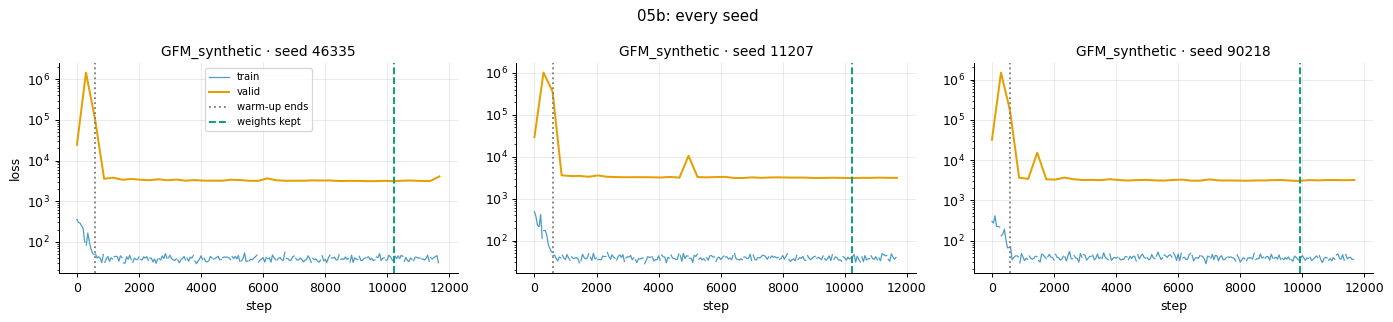

In [8]:
gplt.plot_training(runs, warmup=gd.warmup_steps(max_steps), title="05b: every seed")

<!-- DRAFT: Graeme to edit -->
### 05's reference numbers (3 seeds)

05 kept one model, but its probes need the model in memory. So we refit 05's selected setting
here, with the same 3 seeds and the same data, and probe each fit. Training is deterministic
for a given seed, so these are 05's own models: the check below compares their forecasts with
the ones 05 stored.

In [9]:
def model_05(seed):
    return gd.build_nbeatsx(params, data_a, cfg_a["max_steps"], seed, "GFM_selected")


def reference_extras(nf, data):
    """05's sweep and probes on the test window."""
    return {"sweep": gp.price_sweep(nf, data, report_ids, channel=price_channel),
            **gp.gfm_probes(nf, data, report_ids, calendars)}


runs_a = gd.fit_seeds(model_05, data_a, "05b_reference_05" + PROBE_RUNS,
                      extras=reference_extras)
refit = gd.seed_forecasts(runs_a)[["unique_id", "ds", "GFM_selected_mean"]]
stored = gd.selected_forecasts(cfg_a)
gap = refit.merge(stored, on=["unique_id", "ds"])
print("refit against 05's stored forecasts, largest difference (units):",
      float((gap["GFM_selected_mean"] - gap["GFM_selected"]).abs().max()))
sweep_a = gp.seed_mean_sweep(runs_a)

refit against 05's stored forecasts, largest difference (units): 0.0


<!-- DRAFT: Graeme to edit -->
For both models, each series' sweep and probes are averaged over the three seeds first,
then summarised: the response of the seed-mean model. The per-seed table shows the spread. The
research found each run tends to be all-negative or all-positive in its response (§6), so
watch for one seed that disagrees with the others.

In [10]:
sweep_b = seed_mean([r["sweep"] for r in runs], ["unique_id", "shift"])
el_a = gp.arc_elasticity(sweep_a)
el_b = gp.arc_elasticity(sweep_b)

per_seed = []
for name, model_runs in (("05", runs_a), ("05b", runs)):
    for r in model_runs:
        report = gp.elasticity_report(gp.arc_elasticity(r["sweep"]))
        cut20 = gp.headline(gp.probe_report(r["probe7b"]))
        per_seed.append({"model": name, "seed": r["summary"]["seed"],
                         "cut20_elasticity": cut20["median_elasticity"],
                         "median_e20": report["median_e20"],
                         "share_perverse": report["share_perverse"]})
per_seed = pd.DataFrame(per_seed)
reports = pd.DataFrame({"05 selected": gp.elasticity_report(el_a),
                        "05b synthetic": gp.elasticity_report(el_b)}).T
per_seed.round(3)

,model,seed,cut20_elasticity,median_e20,share_perverse
0,05,46335,-1.750,-1.344,0.013
1,05,11207,-1.763,-1.269,0.026
2,05,90218,-1.737,-1.122,0.012
3,05b,46335,-1.653,-1.297,0.007
4,05b,11207,-1.675,-1.303,0.006
5,05b,90218,-1.729,-1.385,0.004


In [11]:
reports.round(3)

,n,n_estimable,median_e20,share_perverse,share_flat,invariance,median_e5,median_e10
05 selected,680.0,680.0,-1.275,0.007,0.006,1.209,-1.541,-1.456
05b synthetic,680.0,680.0,-1.337,0.003,0.003,1.204,-1.609,-1.514


<!-- DRAFT: Graeme to edit -->
## 5. The echo check: does the model give back the planted lift?

The random promotion calendars are the measuring twin of the planted cuts: one-week cuts of
10–30% in ordinary weeks, with every price input rebuilt, exactly as 05b's copies were built.
So we compare, depth by depth, the lift we planted with the median lift each model predicts
in the cut week. We also draw the lift the data's own elasticity (≈ −3.6) implies.

In the chart (F13), the x-axis is the depth of the one-week cut and the y-axis the median
lift in that week. Dashed lines are references; solid lines are what 05 and 05b give back.

In [12]:
summary_a = gp.probe_report(gp.seed_mean_q([r["probe7b"] for r in runs_a], gp.PROBE_KEYS))
summary_b = gp.probe_report(gp.seed_mean_q([r["probe7b"] for r in runs], gp.PROBE_KEYS))
calendar_a = gp.calendar_report(gp.seed_mean_q([r["calendar"] for r in runs_a], gp.CAL_KEYS))
calendar_b = gp.calendar_report(gp.seed_mean_q([r["calendar"] for r in runs], gp.CAL_KEYS))
empirical_all = gp.empirical_elasticity(train, report_ids).iloc[0]["elasticity"]

echo = pd.DataFrame({"planted": pd.Series(gp.SYNTHETIC_LIFT),
                     "data (empirical e)": pd.Series(
                         gp.implied_lift(empirical_all, gp.CAL_DEPTHS), index=gp.CAL_DEPTHS),
                     "05": calendar_a.set_index("depth")["median_lift"],
                     "05b": calendar_b.set_index("depth")["median_lift"],
                     "depth the model saw": calendar_b.set_index("depth")["median_seen_depth"]})
echo.index.name = "depth"
echo.round(3)

,planted,data (empirical e),05,05b,depth the model saw
depth,,,,,
0.10,0.35,0.467,0.262,0.262,0.032
0.15,0.45,0.806,0.394,0.399,0.079
0.20,0.60,1.252,0.566,0.555,0.122
0.25,1.00,1.848,0.749,0.732,0.167
0.30,1.50,2.660,0.894,0.903,0.210


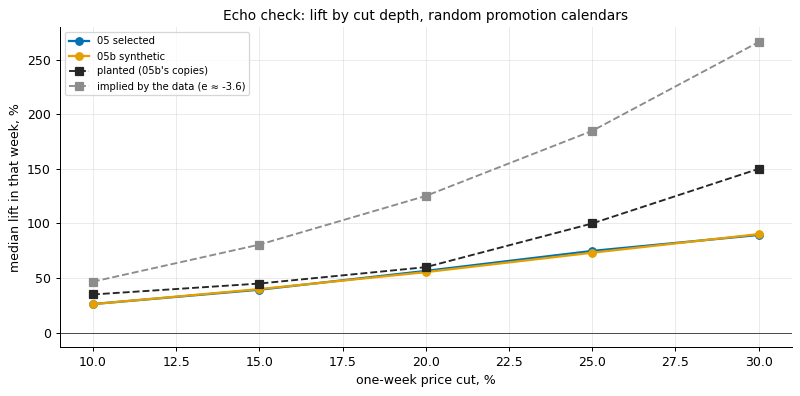

In [13]:
gplt.plot_lift_by_depth({"05 selected": echo["05"], "05b synthetic": echo["05b"]},
                        references={"planted (05b's copies)": echo["planted"],
                                    f"implied by the data (e ≈ {empirical_all:.1f})":
                                        echo["data (empirical e)"]},
                        title="Echo check: lift by cut depth, random promotion calendars")

<!-- DRAFT: Graeme to edit -->
### Reading the result

* The planted line is the answer we wrote in. 05 never saw it; 05b saw it in about 2 weeks
  per copy.
* If 05b's line sits near the planted one, the model learnt the rule. That shows it *can*
  learn a price response from data like this, not that the shop's customers behave so.
* The calendar cut changes the price and the discount depth together, as a planted cut did.
  The last column shows the depth the model was actually given: the data defines depth
  against a 4-week rolling mean that includes the cut week, so a 20% cut reads as ≈ 16%
  at most, less when an earlier cut is still in the mean.
* Here the two solid lines lie on top of each other: ≈ +26% at a 10% cut, ≈ +56% at 20%,
  ≈ +90% at 30%. 05 already gives back about the planted lift up to 20%, so the copies had
  little to teach it there; at 25–30% both fall well short of the planted +100% and +150%.
  Both stay far below the lift the data implies (≈ +125% at 20%).

*Exact numbers vary with seed and hardware.*

<!-- DRAFT: Graeme to edit -->
## 6. Probes: sustained against pulse (F11)

The probes are the research's phase 7b price shocks: −10%, −20%, −30% and +20%, applied to
every test week (**sustained**) or to one week only (**pulse**, test week 5, the first after
the three event weeks). `_price` moves `price_index` alone; `_all` rebuilds every input built
from price; `pulse_all_promo` also sets the promotion flag. Each chart has two panels:

* **left, lift:** median change in units against the shock. A cut should lift sales, so the
  points should sit above zero for the cuts and below zero for the +20% rise.
* **right, spill:** for the pulses only, the median change in the weeks that were *not*
  shocked. Ideally about zero. A large spill means the model smears one week's price across
  the horizon.

The research's pass bar was a median elasticity of −0.3 or stronger, with the right sign
(§5). On this data, with an empirical ≈ −3.6, a model can pass that bar and still be far
weaker than the shop's customers.

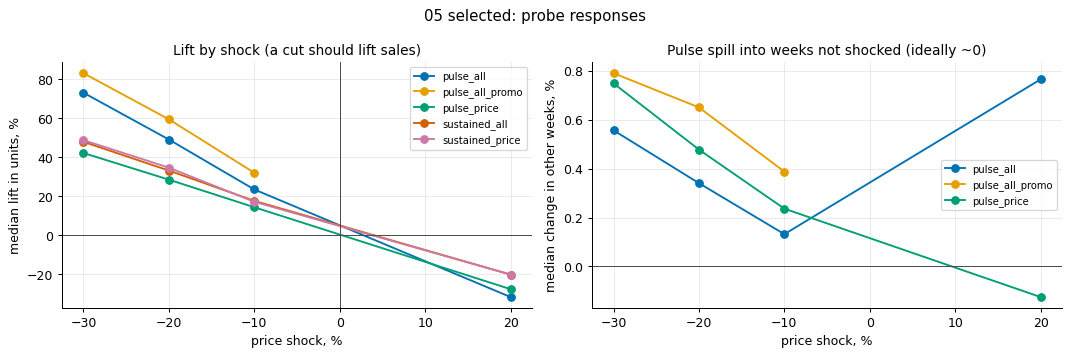

In [14]:
gplt.plot_probe(summary_a, title="05 selected: probe responses")

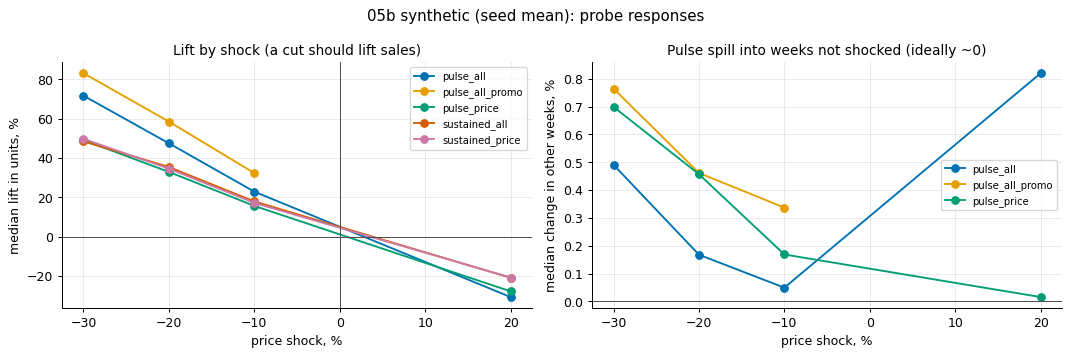

In [15]:
gplt.plot_probe(summary_b, title="05b synthetic (seed mean): probe responses")

<!-- DRAFT: Graeme to edit -->
## 7. Price response by strength and class (F6, F7)

The same charts as 04 and 05, now with 05 and 05b side by side:

* **strength (F6):** one bar per model, split into the share of series that are highly
  elastic (≤ −3), elastic, inelastic, flat (|e| < 0.05) or perverse (e > 0);
* **by class (F7):** median elasticity per sales class A–I, with the empirical values dashed.
  More negative is a stronger response; below the dotted zero line is the right sign.

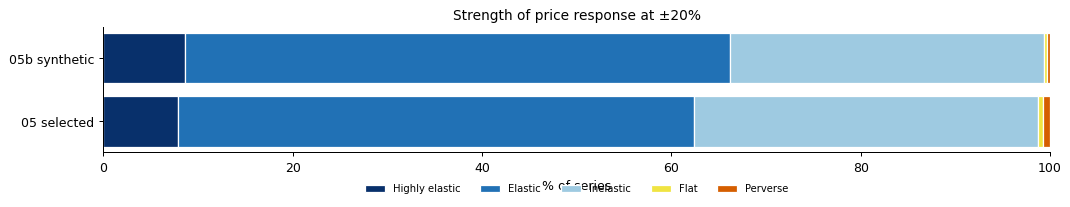

e_arc,Highly elastic,Elastic,Inelastic,Flat,Perverse
05 selected,7.9,54.4,36.3,0.6,0.7
05b synthetic,8.7,57.5,33.2,0.3,0.3


In [16]:
empirical = gp.empirical_elasticity(train, report_ids)
strength = {"05 selected": gp.e20(el_a), "05b synthetic": gp.e20(el_b)}
gplt.plot_elasticity_strength(strength, title="Strength of price response at ±20%")

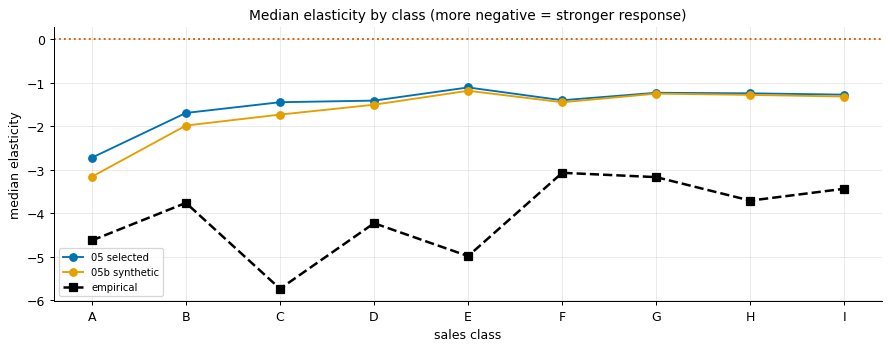

In [17]:
gplt.plot_elasticity_by_class(strength, info, empirical=empirical)

<!-- DRAFT: Graeme to edit -->
### Reading the result

* In F6, look first at the perverse (orange) share: if the cuts helped, it shrinks for 05b.
  Then at how much of each bar is elastic or stronger.
* In F7, a model line closer to the dashed empirical line is more realistic. Both models may
  sit well above it (weaker); the question is whether 05b closes some of the gap.

*Exact numbers vary with seed and hardware.*

<!-- DRAFT: Graeme to edit -->
## 8. Accuracy on the test window

05b's seed-mean forecast against 05's. The synthetic weeks sit only in the copies, so this
shows how far the planted cuts reach the forecasts for real series and real weeks.

The wins chart (F4) has three panels: the share of series 05b wins by class, by count and by
volume (0.5 is a draw); the spread of per-series gains; and one dot per series, head to head
(below the diagonal, 05b is better).

In [18]:
forecasts_b = gd.seed_forecasts(runs).rename(columns={"GFM_synthetic_mean": "GFM_synthetic"})
seed_cols = [c for c in forecasts_b.columns if c.startswith("GFM_synthetic_s")]
forecasts_a = gd.selected_forecasts(cfg_a)          # 05's forecasts, column GFM_selected
both = forecasts_a.merge(forecasts_b, on=["unique_id", "ds"])
rmsse = gd.per_series(gd.score(both, test, train))

seed_medians = rmsse[seed_cols].median()
accuracy = pd.Series({"05 median RMSSE": rmsse["GFM_selected"].median(),
                      "05b median RMSSE": rmsse["GFM_synthetic"].median(),
                      "05b seed spread (max - min)": seed_medians.max() - seed_medians.min(),
                      "noise floor (02)": noise_floor})
accuracy.round(4)

05 median RMSSE                0.5463
05b median RMSSE               0.5461
05b seed spread (max - min)    0.0122
noise floor (02)               0.0048
dtype: float64

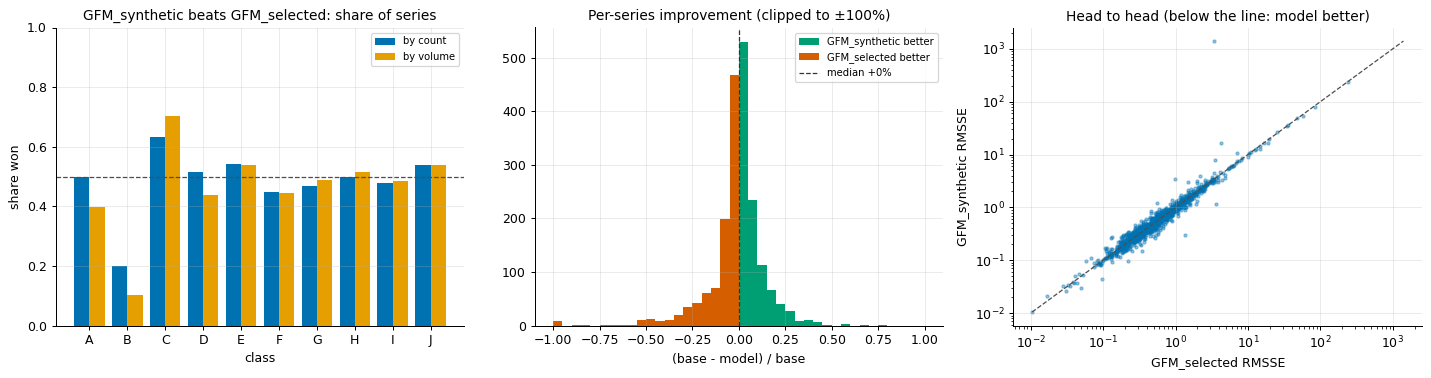

,win_share,win_share_volume,n
sale_class,,,
A,0.500,0.399,4.0
B,0.200,0.101,10.0
C,0.632,0.704,19.0
D,0.516,0.437,31.0
E,0.543,0.538,46.0
F,0.448,0.445,67.0
G,0.469,0.489,96.0
H,0.500,0.514,148.0
I,0.479,0.486,259.0


In [19]:
gplt.plot_wins(rmsse, info, model="GFM_synthetic", baseline="GFM_selected")

<!-- DRAFT: Graeme to edit -->
### Reading the result

* Lead with the median RMSSE: is 05b's within the noise floor of 05's (≈ 0.546 against
  ≈ 0.546)? Yes: the two are equal to the third decimal, well inside the noise floor
  (≈ 0.005). The mean sits alongside
  on the board.
* A win share near 0.5 in every class means the cuts left ordinary forecasts alone. Losses
  bunched in one class point to where the made-up rule hurts.

*Exact numbers vary with seed and hardware.*

In [20]:
fit_seconds = gd.summaries(runs)["fit_seconds"].mean()
gd.save_forecasts(forecasts_b[["unique_id", "ds", "GFM_synthetic"]], "05b_synthetic")
gd.record(forecasts_b[["unique_id", "ds", "GFM_synthetic"]], test, train,
          lab=f"05b synthetic ({len(gd.SEEDS)}-seed mean)", fit_seconds=fit_seconds,
          notes="fit_seconds is per seed")
gd.median_board("05b")

,model,median_rmsse,mean_rmsse,wape,n_series,lab,fit_seconds
0,NHITS_recipe_mean,0.539,1.063,0.251,1999,01 recipe (3-seed mean),249.433
1,NBEATSx_B_cpi_mean,0.540,1.076,0.263,1999,04 price arms (3-seed mean),522.767
2,GFM_synthetic,0.546,1.768,0.265,1999,05b synthetic (3-seed mean),361.200
3,GFM_selected,0.546,1.067,0.257,1999,05 selected (3-seed mean),379.767
4,NBEATSx_C_cpi_over_mean,0.553,1.073,0.267,1999,04 price arms (3-seed mean),575.033
5,NBEATSx_A_features_mean,0.568,1.114,0.286,1999,04 price arms (3-seed mean),501.467
6,NBEATSx_tuned,0.568,1.114,0.286,1999,02 HPO round 1 (3-seed mean),537.767
7,NBEATSx_recipe_mean,0.568,1.114,0.286,1999,01 recipe (3-seed mean),506.900
8,LightGBM,0.569,1.161,0.295,1999,00 baselines (full panel),NaN
9,NBEATSx_cal_hier,0.647,1.170,0.328,1999,03 calendar and hierarchy (3-seed mean),527.233


<!-- DRAFT: Graeme to edit -->
## 9. What the synthetic model does on the example series (F12)

Forecasts at the planned price (base), and with every test-week price 20% lower and higher,
averaged over the three seeds. The lines should keep their order, with −20% on top; the gap
between them is the response, week by week.

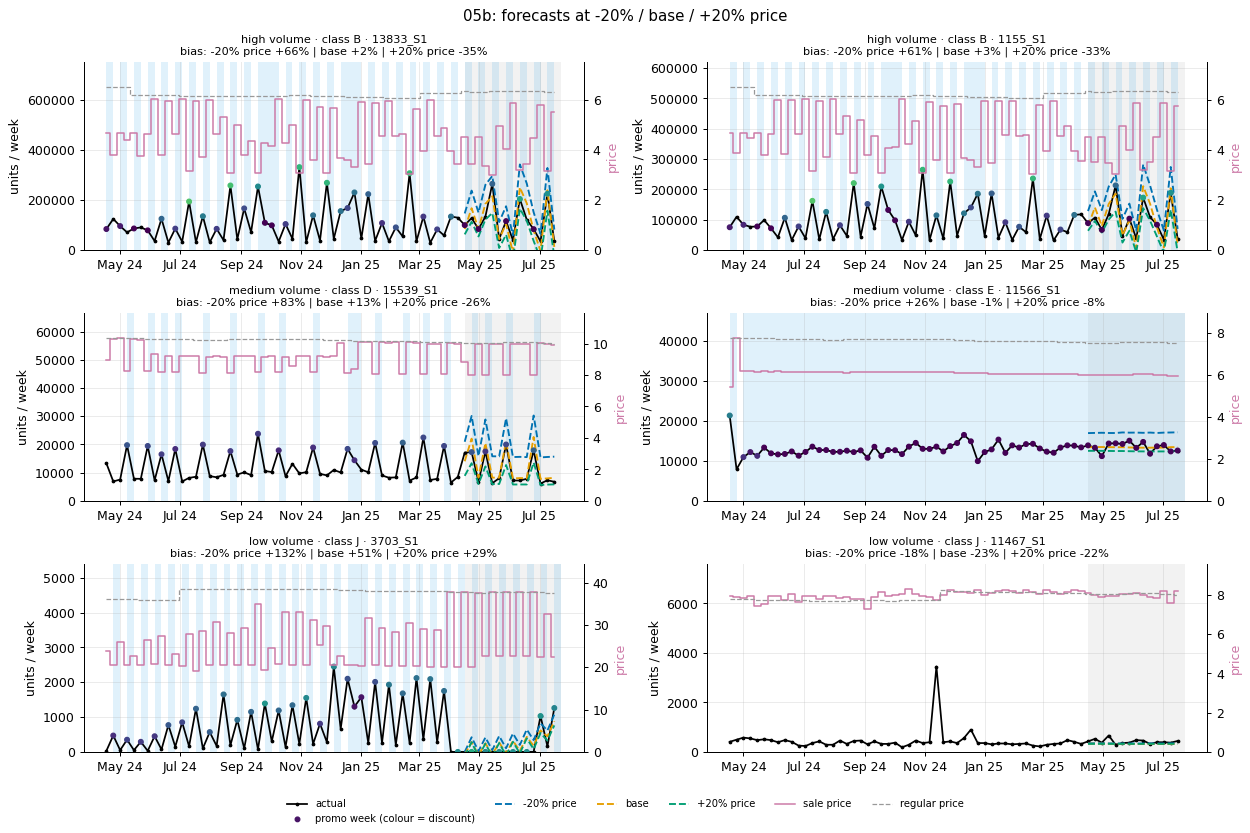

In [21]:
scenarios = seed_mean([r["scenarios"] for r in runs], ["unique_id", "ds"])
gplt.plot_series_price(panel, examples, scenarios, models=["-20% price", "base", "+20% price"],
                       title="05b: forecasts at -20% / base / +20% price")

<!-- DRAFT: Graeme to edit -->
## 10. The same checks on the test window (report only)

The three checks from section 2, now on the test window. They do not change `use`, which
was set on validation in section 3; they show whether the choice held.

In [22]:
test_numbers = pd.DataFrame({"05": response_numbers(runs_a),
                             "05b": response_numbers(runs)}).T
test_checks = {
    "stronger response (one-week 20% cut, more negative)":
        test_numbers.loc["05b", "cut20_elasticity"] < test_numbers.loc["05", "cut20_elasticity"],
    "more right-signed cuts (random calendars)":
        test_numbers.loc["05b", "calendar_right_sign"]
        > test_numbers.loc["05", "calendar_right_sign"],
    "accuracy within the noise floor":
        accuracy["05b median RMSSE"] - accuracy["05 median RMSSE"] <= noise_floor,
}
print(f"later notebooks use: {use} (chosen on validation)")
pd.DataFrame({"validation (chose)": checks, "test (report)": test_checks})

later notebooks use: 05 (chosen on validation)


,validation (chose),test (report)
"stronger response (one-week 20% cut, more negative)",False,False
more right-signed cuts (random calendars),True,False
accuracy within the noise floor,False,True


<!-- DRAFT: Graeme to edit -->
### Reading the result

* On the test window the accuracy check passes, but the response checks do not: 05b's
  one-week 20% cut gives ≈ −1.73 against 05's ≈ −1.79, and the calendars are right-signed
  ≈ 99.3% of the time for both. The validation choice holds: the copies cost nothing in
  accuracy here and add no price response.

*Exact numbers vary with seed and hardware.*

In [23]:
gd.save_config("05b_synthetic", {
    **cfg_a,
    "oversample": cfg_b["oversample"],
    "oversample_added": oversample_added,
    "synthetic": cfg_b["synthetic"],
    "synthetic_seed": synthetic_seed,
    "max_steps": max_steps,
    "seeds": gd.SEEDS,
    "use": use,
    "rule": list(checks),
    "checks": {k: bool(v) for k, v in checks.items()},
    "checks_test": {k: bool(v) for k, v in test_checks.items()},
    "valid": valid_numbers.round(4).to_dict("index"),
    "test_response": test_numbers.round(4).to_dict("index"),
    "elasticity": reports.round(4).to_dict("index"),
    "probes": {"05": summary_a.round(4).to_dict("records"),
               "05b": summary_b.round(4).to_dict("records")},
    "calendar": {"05": calendar_a.round(4).to_dict("records"),
                 "05b": calendar_b.round(4).to_dict("records")},
    "probe_runs": {"05": "05b_reference_05" + PROBE_RUNS, "05b": run_name},
    "echo": echo.round(4).reset_index().to_dict("records"),
    "median_rmsse": {"05": accuracy["05 median RMSSE"], "05b": accuracy["05b median RMSSE"]},
    "saved_model": "05b_synthetic",
    "forecasts": "05b_synthetic",
    "forecast_column": "GFM_synthetic",
})

PosixPath('/home/gdavidson/code/time-series-forecasting-bootcamp/results/day2_full/configs/05b_synthetic.json')

<!-- DRAFT: Graeme to edit -->
## Discussion

* The echo check shows whether the model *can* learn a response it is shown. We planted
  lifts close to the data's own ≈ −3.6. Would you plant the same lifts on a panel where the
  empirical elasticity was −0.5?
* Synthetic cuts sit in copies only. Did they change forecasts for real series in weeks with
  no price change?
* The rule needed all three checks. Which was hardest to pass, and why?
* The first version of this rule moved `price_index` alone, so a cut arrived with no discount
  depth. Which probe would you trust to plan a promotion, and why?

**Try it:** set `cuts_per_copy` to 4, or scale `gp.SYNTHETIC_LIFT` down by half, and rerun the
echo check. Does the measured lift follow the planted one?